# 03 · Rao-style hierarchical generative predictive coding, convolutional: MNIST reconstruction

- 02 with convolutional layers (ConvHPC); 30 inference steps per batch, 10 epochs.


Device: mps
Epoch 001/10 | Train Energy 5.0416 | Test Energy 2.2210 | Test MSE 0.000392 | 21.3s
Epoch 002/10 | Train Energy 1.8688 | Test Energy 1.6377 | Test MSE 0.000252 | 19.7s
Epoch 003/10 | Train Energy 1.5650 | Test Energy 1.4647 | Test MSE 0.000255 | 19.8s
Epoch 004/10 | Train Energy 1.3475 | Test Energy 1.2462 | Test MSE 0.000230 | 19.4s
Epoch 005/10 | Train Energy 1.1776 | Test Energy 1.1174 | Test MSE 0.000215 | 19.3s
Epoch 006/10 | Train Energy 1.1056 | Test Energy 1.0431 | Test MSE 0.000146 | 19.3s
Epoch 007/10 | Train Energy 0.9770 | Test Energy 0.9622 | Test MSE 0.000122 | 20.2s
Epoch 008/10 | Train Energy 1.0217 | Test Energy 1.0471 | Test MSE 0.000160 | 19.8s
Epoch 009/10 | Train Energy 1.0675 | Test Energy 1.0193 | Test MSE 0.000121 | 19.4s
Epoch 010/10 | Train Energy 0.9876 | Test Energy 0.9692 | Test MSE 0.000091 | 19.5s


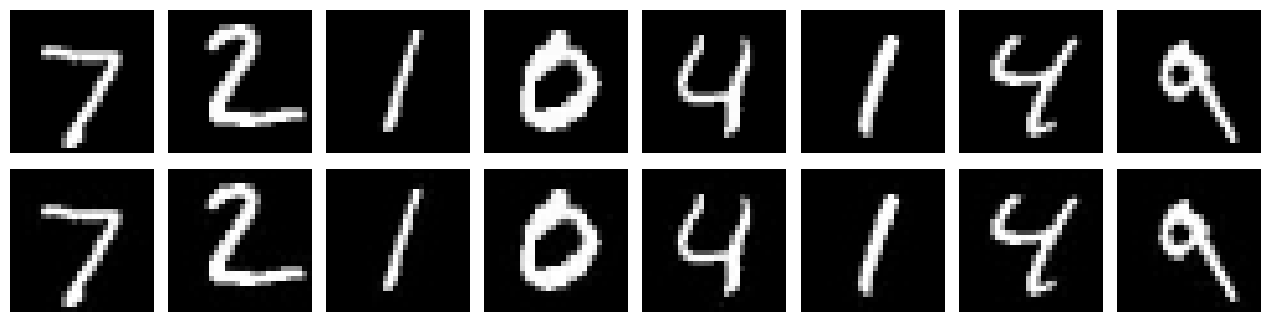

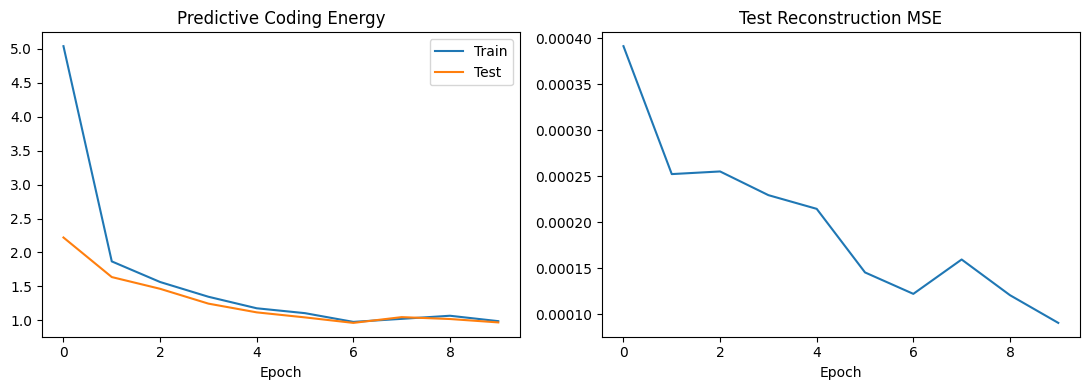

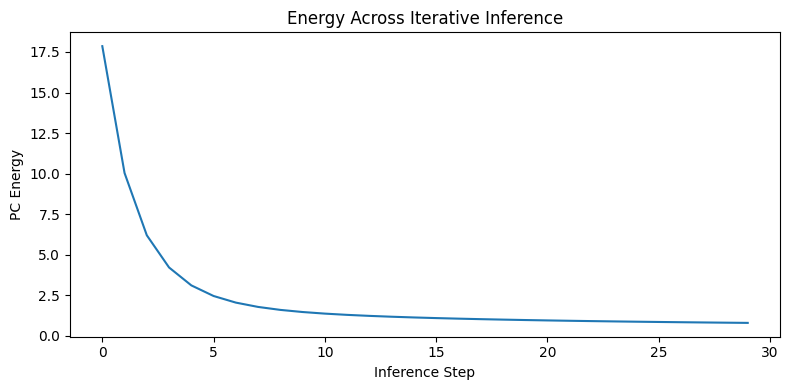

In [1]:

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
import time


# 1. CONFIGURATION
torch.manual_seed(1234)

from archive.utils import get_device
DEVICE = get_device()

BATCH_SIZE = 64
EPOCHS = 10
INFERENCE_STEPS = 30
INFERENCE_LR = 0.02
LEARNING_RATE = 0.0005
ACTIVITY_PRIOR = 0.001
WEIGHT_DECAY = 0.00001

train_loader = DataLoader(MNIST("data", train=True, download=True, transform=ToTensor()), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(MNIST("data", train=False, download=True, transform=ToTensor()), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Device:", DEVICE)


# 2. RAO-INSPIRED CONVOLUTIONAL PREDICTIVE CODING
class ConvHPC:

    def __init__(self, device):
        self.device = device

        # Generative weights, higher state predicts lower state.
        self.W1 = torch.empty(16, 1, 4, 4, device=device)
        self.W2 = torch.empty(32, 16, 4, 4, device=device)
        self.W3 = torch.empty(64, 32, 3, 3, device=device)

        nn.init.kaiming_normal_(self.W1, nonlinearity="relu")
        nn.init.kaiming_normal_(self.W2, nonlinearity="relu")
        nn.init.kaiming_normal_(self.W3, nonlinearity="relu")

        self.weights = [self.W1, self.W2, self.W3]
        self.strides = [2, 2, 1]
        self.paddings = [1, 1, 1]

        self.m = [torch.zeros_like(w) for w in self.weights]
        self.v = [torch.zeros_like(w) for w in self.weights]
        self.step = 0

    def activation(self, z):
        return F.relu(z)

    def derivative(self, z):
        return (z > 0).to(z.dtype)

    # 3. TOP-DOWN PREDICTIONS
    def top_down_prediction(self, z1, z2, z3):
        p0 = F.conv_transpose2d(self.activation(z1), self.W1, stride=2, padding=1)
        p1 = F.conv_transpose2d(self.activation(z2), self.W2, stride=2, padding=1)
        p2 = F.conv_transpose2d(self.activation(z3), self.W3, stride=1, padding=1)
        return p0, p1, p2

    # 4. BOTTOM-UP PREDICTION ERRORS
    def bottom_up_prediction_error(self, x, z1, z2, p0, p1, p2):
        e0 = x - p0
        e1 = z1 - p1
        e2 = z2 - p2
        return e0, e1, e2

    # 5. FEEDFORWARD STATE INITIALIZATION
    @torch.no_grad()
    def initialize_states(self, x):
        z1 = F.relu(F.conv2d(x, self.W1, stride=2, padding=1))
        z2 = F.relu(F.conv2d(z1, self.W2, stride=2, padding=1))
        z3 = F.relu(F.conv2d(z2, self.W3, stride=1, padding=1))
        return z1, z2, z3

    # 6. ITERATIVE PREDICTIVE CODING INFERENCE
    @torch.no_grad()
    def infer(self, x, steps=INFERENCE_STEPS, track_energy=False):
        z1, z2, z3 = self.initialize_states(x)
        energy_trace = []

        for _ in range(steps):

            # Higher -> Lower predictions
            p0, p1, p2 = self.top_down_prediction(z1, z2, z3)

            # Lower -> Higher prediction errors
            e0, e1, e2 = self.bottom_up_prediction_error(x, z1, z2, p0, p1, p2)

            # Error-modulated hidden-state inference
            dz1 = F.conv2d(e0, self.W1, stride=2, padding=1) * self.derivative(z1) - e1 - ACTIVITY_PRIOR * z1.sign()
            dz2 = F.conv2d(e1, self.W2, stride=2, padding=1) * self.derivative(z2) - e2 - ACTIVITY_PRIOR * z2.sign()
            dz3 = F.conv2d(e2, self.W3, stride=1, padding=1) * self.derivative(z3) - ACTIVITY_PRIOR * z3.sign()

            # Numerical stability
            dz1 = dz1.clamp(-5.0, 5.0)
            dz2 = dz2.clamp(-5.0, 5.0)
            dz3 = dz3.clamp(-5.0, 5.0)

            z1 = z1 + INFERENCE_LR * dz1
            z2 = z2 + INFERENCE_LR * dz2
            z3 = z3 + INFERENCE_LR * dz3

            if track_energy:
                q0, q1, q2 = self.top_down_prediction(z1, z2, z3)
                r0, r1, r2 = self.bottom_up_prediction_error(x, z1, z2, q0, q1, q2)
                energy_trace.append(self.compute_energy(r0, r1, r2, z1, z2, z3).item())

        p0, p1, p2 = self.top_down_prediction(z1, z2, z3)
        e0, e1, e2 = self.bottom_up_prediction_error(x, z1, z2, p0, p1, p2)

        energy = self.compute_energy(e0, e1, e2, z1, z2, z3)

        return p0, (z1, z2, z3), (e0, e1, e2), energy, energy_trace

    # 7. PREDICTIVE CODING ENERGY
    def compute_energy(self, e0, e1, e2, z1, z2, z3):
        prediction_energy = 0.5 * (e0.square().flatten(1).sum(1) + e1.square().flatten(1).sum(1) + e2.square().flatten(1).sum(1)).mean()
        activity_energy = ACTIVITY_PRIOR * (z1.abs().flatten(1).sum(1) + z2.abs().flatten(1).sum(1) + z3.abs().flatten(1).sum(1)).mean()
        return prediction_energy + activity_energy

    # 8. LOCAL ERROR-BASED CONV WEIGHT LEARNING
    @torch.no_grad()
    def local_weight_gradients(self, states, errors):
        gradients = []

        for weight, state, error, stride, padding in zip(self.weights, states, errors, self.strides, self.paddings):

            # Gradient of local prediction mismatch only.
            # Uses the adjoint convolution identity, without
            # global loss.backward() or end-to-end autograd.
            local_gradient = torch.nn.grad.conv2d_weight(error, weight.shape, self.activation(state), stride=stride, padding=padding)
            local_gradient = -local_gradient / state.shape[0] + WEIGHT_DECAY * weight

            gradients.append(local_gradient)

        return gradients

    # 9. LOCAL ADAM OPTIMIZER
    @torch.no_grad()
    def update_weights(self, gradients):
        self.step += 1

        for i, (w, g) in enumerate(zip(self.weights, gradients)):
            g = g.clamp(-1.0, 1.0)

            self.m[i].mul_(0.9).add_(g, alpha=0.1)
            self.v[i].mul_(0.999).addcmul_(g, g, value=0.001)

            m_hat = self.m[i] / (1 - 0.9 ** self.step)
            v_hat = self.v[i] / (1 - 0.999 ** self.step)

            w.addcdiv_(m_hat, v_hat.sqrt() + 1e-8, value=-LEARNING_RATE)

    # 10. TRAIN ONE BATCH
    @torch.no_grad()
    def train_batch(self, x):
        reconstruction, states, errors, energy, _ = self.infer(x)
        gradients = self.local_weight_gradients(states, errors)
        self.update_weights(gradients)
        return energy.item()


# 11. TEST EVALUATION
@torch.no_grad()
def evaluate(model, loader):
    total_mse = 0.0
    total_energy = 0.0
    total_pixels = 0
    total_images = 0

    for images, _ in loader:
        x = images.to(DEVICE)
        reconstruction, _, _, energy, _ = model.infer(x)

        total_mse += (x - reconstruction).square().sum().item()
        total_energy += energy.item() * x.shape[0]
        total_pixels += x.numel()
        total_images += x.shape[0]

    return total_mse / total_pixels, total_energy / total_images


# 12. INITIALIZE AND TRAIN
model = ConvHPC(DEVICE)

history = {"train_energy": [], "test_energy": [], "test_mse": []}

for epoch in range(1, EPOCHS + 1):
    start = time.perf_counter()
    running_energy = 0.0
    total = 0

    for images, _ in train_loader:
        x = images.to(DEVICE)

        energy = model.train_batch(x)
        running_energy += energy * x.shape[0]
        total += x.shape[0]

    train_energy = running_energy / total
    test_mse, test_energy = evaluate(model, test_loader)

    history["train_energy"].append(train_energy)
    history["test_energy"].append(test_energy)
    history["test_mse"].append(test_mse)

    print(f"Epoch {epoch:03d}/{EPOCHS} | Train Energy {train_energy:.4f} | Test Energy {test_energy:.4f} | Test MSE {test_mse:.6f} | {time.perf_counter()-start:.1f}s")


# 13. VISUALIZE ORIGINAL VS RECONSTRUCTED IMAGES
@torch.no_grad()
def show_reconstructions(model, loader, count=8):
    images, _ = next(iter(loader))
    original = images[:count].to(DEVICE)

    reconstructed = model.infer(original)[0]

    fig, axes = plt.subplots(2, count, figsize=(count * 1.6, 3.5))

    for j in range(count):
        axes[0, j].imshow(original[j, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[1, j].imshow(reconstructed[j, 0].cpu().clamp(0, 1), cmap="gray", vmin=0, vmax=1)

        axes[0, j].axis("off")
        axes[1, j].axis("off")

    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Reconstructed")

    plt.tight_layout()
    plt.show()

show_reconstructions(model, test_loader)


# 14. TRAINING GRAPHS
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history["train_energy"], label="Train")
axes[0].plot(history["test_energy"], label="Test")
axes[0].set_title("Predictive Coding Energy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["test_mse"])
axes[1].set_title("Test Reconstruction MSE")
axes[1].set_xlabel("Epoch")

plt.tight_layout()
plt.show()


# 15. INFERENCE CONVERGENCE DIAGNOSTIC

images, _ = next(iter(test_loader))
sample = images[:8].to(DEVICE)

_, _, _, _, energy_trace = model.infer(sample, track_energy=True)

plt.figure(figsize=(8, 4))
plt.plot(energy_trace)
plt.title("Energy Across Iterative Inference")
plt.xlabel("Inference Step")
plt.ylabel("PC Energy")
plt.tight_layout()
plt.show()
